<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/explore_miteco_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explorar los datos del MITECO (Reto Demográfico) para Asturias

**Qué hace este cuaderno:** lee los zip descargados del MITECO, se queda con los 78 concejos
de Asturias, junta todos los indicadores en **una sola tabla** (una fila por concejo) y la explora:
resumen, extremos, mapas y una comparación con los datos de OSM del MVP.

**Lo que ya sabemos (comprobado con `Centros_EdPrimaria_2022.zip`):**
- Cada zip es un *shapefile* con los 8.131 municipios de España como polígonos (ETRS89).
- Todos comparten las columnas de identificación (`nombre`, `codmun_ine`, `ccaa`…) y
  **cada uno añade solo su indicador** (en primaria: `centr_ed_p`).
- Por eso los juntamos por `codmun_ine` (código INE del municipio).

**Lo que este cuaderno debe aclarar:** qué columnas trae cada zip y en qué unidad están los
tiempos (¿minutos?). Los metadatos dicen que el tiempo al hospital viene de un campo `TPO_HOSP`
numérico, pero no dicen la unidad.

**Cómo usarlo:** pon los zip en la misma carpeta que el cuaderno (o cambia `CARPETA`) y ejecuta
todo. Funciona en local (Jupyter/VS Code) y en Colab (sube los zip al panel de archivos).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# geopandas reads shapefiles (also directly from a .zip); matplotlib draws the maps.
%pip install -q geopandas matplotlib

In [3]:
import glob
import json
import os
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Folder where the MITECO .zip files are. "." = same folder as the notebook.
CARPETA = "/content/drive/MyDrive/tfg/miteco_data"
# Value of the "ccaa" column used to keep only Asturias.
CCAA = "Principado de Asturias"
# OSM data from the MVP (optional, used in the last section). Leave as is if you don't have it.
FICHERO_OSM = "datos_Candamo.json"
CONCEJO_OSM = "Candamo"

# Show all columns when printing tables.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1. Leer cada zip y ver qué trae

Para cada fichero imprime: tipo de geometría, número de filas, sistema de coordenadas y
**las columnas que no son de identificación**, es decir, el indicador que aporta ese zip.

In [4]:
# Columns that every MITECO file shares (identification + geometry), checked on the primary-school file.
COMUNES = {"objectid", "natcode", "nombre", "cod_nut1", "cod_nut2", "cod_nut3", "codmun_ine",
           "ccaa", "cod_ccaa", "cod_pro", "provincia", "geometry",
           "st_area(shape)", "st_perimeter(shape)", "st_area_sh", "st_perimet"}

zips = sorted(glob.glob(os.path.join(CARPETA, "*.zip")))
print(f"{len(zips)} zip encontrados en {os.path.abspath(CARPETA)}\n")

capas = {}  # file name -> GeoDataFrame (whole Spain)
for ruta in zips:
    nombre = os.path.basename(ruta).removesuffix(".zip")
    try:
        # Unzip into a folder with the same name and read the .shp from there
        # (reading the .zip directly fails with some GDAL versions, e.g. in Colab).
        destino = os.path.join("/content/miteco", nombre)  # unzip to local disk, not Drive
        with zipfile.ZipFile(ruta) as z:
            z.extractall(destino)
        shp = glob.glob(os.path.join(destino, "**", "*.shp"), recursive=True)[0]
        gdf = gpd.read_file(shp)
    except Exception as e:  # a zip that is not a shapefile: report and skip it
        print(f"✗ {nombre}: no se pudo leer ({e})\n")
        continue
    capas[nombre] = gdf
    propias = [c for c in gdf.columns if c.lower() not in COMUNES]
    print(f"✓ {nombre}")
    print(f"   geometría: {gdf.geom_type.unique().tolist()} | filas: {len(gdf)} | CRS: {gdf.crs}")
    print(f"   columnas propias (el indicador): {propias}")
    print(f"   todas: {list(gdf.columns)}\n")

5 zip encontrados en /content/drive/MyDrive/tfg/miteco_data

✓ Centros_EdPrimaria_2022
   geometría: ['Polygon', 'MultiPolygon'] | filas: 8131 | CRS: EPSG:4258
   columnas propias (el indicador): ['centr_ed_p']
   todas: ['objectid', 'natcode', 'nombre', 'cod_nut1', 'cod_nut2', 'cod_nut3', 'codmun_ine', 'ccaa', 'cod_ccaa', 'cod_pro', 'provincia', 'centr_ed_p', 'geometry']

✓ Farmacias_2023
   geometría: ['Polygon', 'MultiPolygon'] | filas: 8131 | CRS: EPSG:4258
   columnas propias (el indicador): ['farmacias']
   todas: ['objectid', 'natcode', 'nombre', 'cod_nut1', 'cod_nut2', 'cod_nut3', 'codmun_ine', 'ccaa', 'cod_ccaa', 'cod_pro', 'provincia', 'farmacias', 'geometry']

✓ Porcentaje_Pob_Cob100
   geometría: ['Polygon', 'MultiPolygon'] | filas: 8131 | CRS: EPSG:4258
   columnas propias (el indicador): ['cobert_100']
   todas: ['objectid', 'natcode', 'nombre', 'cod_nut1', 'cod_nut2', 'cod_nut3', 'codmun_ine', 'ccaa', 'cod_ccaa', 'cod_pro', 'provincia', 'cobert_100', 'geometry']

✓ Tiemp

## 2. Juntar todo en una tabla de Asturias

Se toma la geometría y la identificación del primer fichero, y de cada fichero solo sus columnas
propias, unidas por `codmun_ine`. Si algún concejo no casa, se avisa.

In [5]:
if not capas:
    raise RuntimeError("No se ha leído ningún zip: revisa CARPETA y la salida de la sección 1.")

asturias = None
for nombre, gdf in capas.items():
    ast = gdf[gdf["ccaa"] == CCAA]
    if asturias is None:
        # First file gives the base: identification columns + polygon.
        base = [c for c in ["codmun_ine", "nombre", "provincia", "geometry"] if c in ast.columns]
        asturias = ast[base].copy()
    propias = [c for c in ast.columns if c.lower() not in COMUNES]
    # If two files share an indicator name, prefix it with the file name to keep both.
    renombre = {c: f"{nombre}__{c}" for c in propias if c in asturias.columns}
    asturias = asturias.merge(ast[["codmun_ine"] + propias].rename(columns=renombre),
                              on="codmun_ine", how="left")

asturias = asturias.sort_values("nombre").reset_index(drop=True)
INDICADORES = [c for c in asturias.columns if c not in ("codmun_ine", "nombre", "provincia", "geometry")]

print("Concejos de Asturias:", len(asturias), "(esperado: 78)")
print("Indicadores:", INDICADORES)
print("\nValores vacíos por indicador (concejos sin dato):")
print(asturias[INDICADORES].isna().sum().to_string())
asturias.drop(columns="geometry").head(10)

Concejos de Asturias: 78 (esperado: 78)
Indicadores: ['centr_ed_p', 'farmacias', 'cobert_100', 'nom_atp_at', 'tipo_atp_a', 'nom_hosp', 'tipo_hosp']

Valores vacíos por indicador (concejos sin dato):
centr_ed_p    0
farmacias     0
cobert_100    0
nom_atp_at    0
tipo_atp_a    0
nom_hosp      0
tipo_hosp     0


,codmun_ine,nombre,provincia,centr_ed_p,farmacias,cobert_100,nom_atp_at,tipo_atp_a,nom_hosp,tipo_hosp
0,33001,Allande,Asturias,2,2,40.913978,A-63,44.903,HOSPITAL CARMEN Y SEVERO OCHOA,18.964
1,33002,Aller,Asturias,7,6,46.989024,A-66,14.690,HOSPITAL VITAL ALVAREZ BUYLLA,17.240
2,33003,Amieva,Asturias,0,1,20.896657,A-8,29.026,HOSPITAL DEL ORIENTE DE ASTURIAS FRANCISCO GRA...,19.729
3,33004,Avilés,Asturias,21,37,60.960591,AS-392,2.094,FUNDACION HOSPITAL DE AVILES,1.425
4,33005,Belmonte de Miranda,Asturias,1,1,44.975459,A-63,15.205,CENTRO MEDICO DE ASTURIAS,32.360
5,33006,Bimenes,Asturias,1,1,46.674017,A-64,8.423,FUNDACION SANATORIO ADARO,13.313
6,33007,Boal,Asturias,1,2,90.252708,A-8,18.236,HOSPITAL DE JARRIO,21.651
7,33008,Cabrales,Asturias,1,1,84.227936,A-8,19.540,HOSPITAL DEL ORIENTE DE ASTURIAS FRANCISCO GRA...,34.917
8,33009,Cabranes,Asturias,1,1,10.346696,A-8,10.174,CLINICA PSIQUIATRICA SOMIO,22.725
9,33010,Candamo,Asturias,1,1,76.842523,A-63,5.940,CENTRO MEDICO DE ASTURIAS,16.470


## 3. Resumen de cada indicador

- Para columnas **numéricas**: mínimo, media, máximo… Si un tiempo va de ~0 a ~100, son
  probablemente minutos; si va de 0 a 2, horas. **Esto es lo que decide la unidad: anótalo.**
- Para columnas de **texto** (p. ej. el nombre del hospital de referencia): valores más frecuentes.

In [6]:
numericas = [c for c in INDICADORES if pd.api.types.is_numeric_dtype(asturias[c])]
texto = [c for c in INDICADORES if c not in numericas]

if numericas:
    display(asturias[numericas].describe().round(2).T)
for c in texto:
    print(f"\n{c}: {asturias[c].nunique()} valores distintos. Los más frecuentes:")
    print(asturias[c].value_counts().head(10).to_string())

,count,mean,std,min,25%,50%,75%,max
centr_ed_p,78.0,3.78,7.50,0.00,1.00,1.00,3.00,49.00
farmacias,78.0,5.83,16.00,0.00,1.00,2.00,4.00,105.00
cobert_100,78.0,47.02,33.82,0.00,14.81,46.02,79.24,98.17
tipo_atp_a,78.0,14.51,14.43,0.45,2.77,10.45,21.03,56.43
tipo_hosp,78.0,19.71,13.36,0.95,10.10,17.32,29.00,54.18



nom_atp_at: 11 valores distintos. Los más frecuentes:
nom_atp_at
A-8       41
A-63      14
A-66       6
A-64       6
AS-I       5
AS-392     1
CL-631     1
GJ-81      1
A-6        1
AS-II      1

nom_hosp: 15 valores distintos. Los más frecuentes:
nom_hosp
HOSPITAL DE JARRIO                                          15
CENTRO MEDICO DE ASTURIAS                                   14
HOSPITAL DEL ORIENTE DE ASTURIAS FRANCISCO GRANDE COVIAN    11
HOSPITAL UNIVERSITARIO SAN AGUSTIN                           7
FUNDACION SANATORIO ADARO                                    6
HOSPITAL CARMEN Y SEVERO OCHOA                               5
HOSPITAL VALLE DEL NALON                                     4
FUNDACION HOSPITAL DE AVILES                                 3
HOSPITAL VITAL ALVAREZ BUYLLA                                3
HOSPITAL SIERRALLANA                                         3


## 4. Extremos: qué concejos están mejor y peor

Sirve para comprobar que los datos tienen sentido con lo que conoces de Asturias
(p. ej. Oviedo y Gijón con muchos servicios, concejos de montaña con tiempos altos).

In [7]:
for c in numericas:
    orden = asturias[["nombre", c]].dropna().sort_values(c)
    print(f"── {c} ──")
    print("  más bajos:", ", ".join(f"{n} ({v:g})" for n, v in orden.head(5).values))
    print("  más altos:", ", ".join(f"{n} ({v:g})" for n, v in orden.tail(5).values))
    print("  concejos con 0:", (orden[c] == 0).sum(), "\n")

── centr_ed_p ──
  más bajos: Amieva (0), Santo Adriano (0), Peñamellera Alta (0), Pesoz (0), Yernes y Tameza (0)
  más altos: Mieres (13), Siero (16), Avilés (21), Oviedo (39), Gijón (49)
  concejos con 0: 5 

── farmacias ──
  más bajos: Caravia (0), Degaña (0), Illano (0), Pesoz (0), Ponga (0)
  más altos: Langreo (23), Mieres (24), Avilés (37), Oviedo (89), Gijón (105)
  concejos con 0: 10 

── cobert_100 ──
  más bajos: Castrillón (0), El Franco (0), Degaña (0), Nava (0), Ribadesella (0)
  más altos: Santo Adriano (95.9237), Morcín (96.3009), Cangas del Narcea (96.5891), Coaña (97.0854), Llanera (98.1665)
  concejos con 0: 14 

── tipo_atp_a ──
  más bajos: Sariego (0.447), Muros de Nalón (0.527), Caravia (0.613), Villaviciosa (0.785), Corvera de Asturias (0.801)
  más altos: Cangas del Narcea (42.435), Allande (44.903), Pesoz (47.137), Grandas de Salime (53.055), Ibias (56.43)
  concejos con 0: 0 

── tipo_hosp ──
  más bajos: Cangas del Narcea (0.946), Parres (1.074), Avilés (1.

## 5. Mapas

Un mapa por indicador numérico. Los concejos grises no tienen dato.

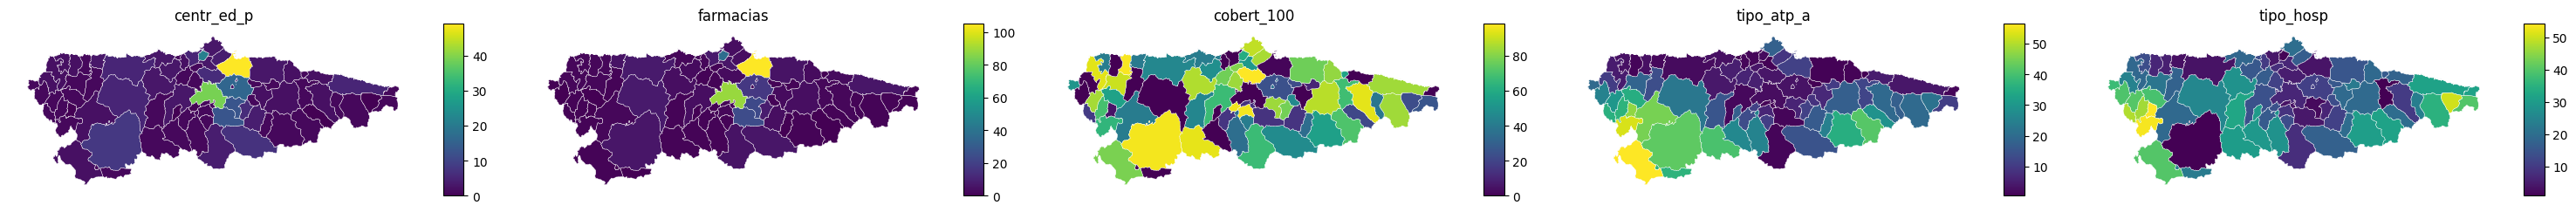

In [8]:
if numericas:
    n = len(numericas)
    fig, ejes = plt.subplots(1, n, figsize=(6 * n, 5), squeeze=False)
    for eje, c in zip(ejes[0], numericas):
        asturias.plot(column=c, ax=eje, legend=True, cmap="viridis",
                      edgecolor="white", linewidth=0.3,
                      missing_kwds={"color": "lightgrey"})
        eje.set_title(c)
        eje.set_axis_off()
    plt.tight_layout()
    plt.show()

## 6. Un concejo en detalle

Cambia el nombre para ver la fila completa de cualquier concejo.

In [9]:
asturias[asturias["nombre"] == CONCEJO_OSM].drop(columns="geometry").T

,9
codmun_ine,33010
nombre,Candamo
provincia,Asturias
centr_ed_p,1
farmacias,1
cobert_100,76.842523
nom_atp_at,A-63
tipo_atp_a,5.94
nom_hosp,CENTRO MEDICO DE ASTURIAS
tipo_hosp,16.47


## 7. Comparar con OSM (los datos del MVP)

Cuenta cuántos servicios de OSM caen **dentro del polígono del concejo** (el MVP descargaba
también 10 km alrededor, que aquí se descartan) y los pone al lado del dato del MITECO.

**Cuidado al interpretar (inferencia):** no miden exactamente lo mismo. El "colegio" de OSM
incluye institutos, infantil y privados; el MITECO cuenta centros de primaria. Una diferencia
grande no dice quién se equivoca, pero **sí es un dato para la sección de riesgos de la PEC1**.

In [10]:
# Which MITECO column corresponds to each OSM type, if present.
EQUIVALENCIAS = {"farmacia": "farmacias", "colegio": "centr_ed_p"}

if not os.path.exists(FICHERO_OSM):
    print(f"No encuentro {FICHERO_OSM}: copia aquí el JSON del MVP para hacer la comparación.")
else:
    with open(FICHERO_OSM, encoding="utf-8") as f:
        osm = json.load(f)
    puntos = gpd.GeoDataFrame(
        osm["servicios"],
        geometry=gpd.points_from_xy([s["lon"] for s in osm["servicios"]],
                                    [s["lat"] for s in osm["servicios"]]),
        crs="EPSG:4326",
    ).to_crs(asturias.crs)  # same coordinate system as the MITECO polygons
    poligono = asturias[asturias["nombre"] == CONCEJO_OSM]
    dentro = puntos[puntos.within(poligono.geometry.iloc[0])]  # points inside the concejo

    print(f"Servicios OSM descargados: {len(puntos)} | dentro de {CONCEJO_OSM}: {len(dentro)}\n")
    filas = []
    for tipo, cuenta in dentro["tipo"].value_counts().items():
        col = EQUIVALENCIAS.get(tipo)
        dato = poligono[col].iloc[0] if col in poligono.columns else "—"
        filas.append({"tipo OSM": tipo, "OSM dentro del concejo": cuenta,
                      "MITECO": dato, "columna MITECO": col or "—"})
    display(pd.DataFrame(filas))
    print("\nServicios OSM dentro del concejo:")
    display(dentro[["tipo", "nombre", "id"]].sort_values("tipo"))

No encuentro datos_Candamo.json: copia aquí el JSON del MVP para hacer la comparación.


## 8. Guardar la tabla de Asturias

- `asturias_miteco.gpkg`: con polígonos (se abre en QGIS o con `gpd.read_file`).
- `asturias_miteco.csv`: solo los datos, para mirar en Excel o cargar rápido.

In [11]:
asturias.to_file("asturias_miteco.gpkg", driver="GPKG")
asturias.drop(columns="geometry").to_csv("asturias_miteco.csv", index=False)
print("Guardado: asturias_miteco.gpkg y asturias_miteco.csv")

Guardado: asturias_miteco.gpkg y asturias_miteco.csv


## Qué mirar al terminar

1. **Unidad de los tiempos** (sección 3): ¿minutos? Si no está claro, busca la "Descripción
   del servicio" en la web del MITECO y cítala.
2. **Qué significa `Porcentaje_Pob_Cob100`**: por el nombre, % de población con cobertura de
   100 Mb/s (inferencia; compruébalo en la descripción).
3. **Si hay concejos sin dato** (sección 2) y cuáles.
4. **La comparación con OSM** (sección 7): anota la diferencia como riesgo de datos en la PEC1.
5. Recuerda que son **datos por concejo**: sirven para validar y para preguntas a nivel de
   concejo, no para "el pueblo X".